<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# Time Series Forecasting with PyCaret
---
<small>© 2026 Decoded Limited. All rights reserved.</small>

## Welcome
Build a forecasting pipeline: load, feature engineering, model comparison, tuning, deploy.
| Step | Activity |
| ---- | -------- |
| 1 | Load data |
| 2 | Feature engineering |
| 3 | Setup |
| 4 | Compare models |
| 5 | Tune best |
| 6 | Evaluate |
| 7 | Deploy (save/load) |

## 0. Dependencies

In [48]:
# Install if needed
# !pip install pycaret ydata-profiling pandas numpy scikit-learn
import numpy as np
import pandas as pd
# Import seasonal_decompose for time series decomposition
from statsmodels.tsa.seasonal import seasonal_decompose
# Import pycaret time series modules
from pycaret.time_series import *
from pycaret.plots.time_series import forecast, decomposition, acf, pacf, residual_diagnostics
print("Ready.")

Ready.


## 1. Load data

In [36]:
# Create synthetic monthly sales data for demonstration
np.random.seed(42)
dates = pd.date_range(start="2018-01-01", periods=96, freq="ME")
sales = 120 + np.arange(96) * 0.85 + 22 * np.sin(2 * np.pi * np.arange(96) / 12) + np.random.normal(0, 6, 96)
ts_data = pd.DataFrame({"date": dates, "sales": sales.round(2), "promotion": (np.arange(96) % 6 <= 1).astype(int)})
ts_data.set_index("date", inplace=True)
print(ts_data.tail())
print("Shape:", ts_data.shape)

             sales  promotion
date                         
2025-08-31  192.16          1
2025-09-30  174.94          0
2025-10-31  175.08          0
2025-11-30  178.49          0
2025-12-31  180.97          0
Shape: (96, 2)


## 2. Quick EDA

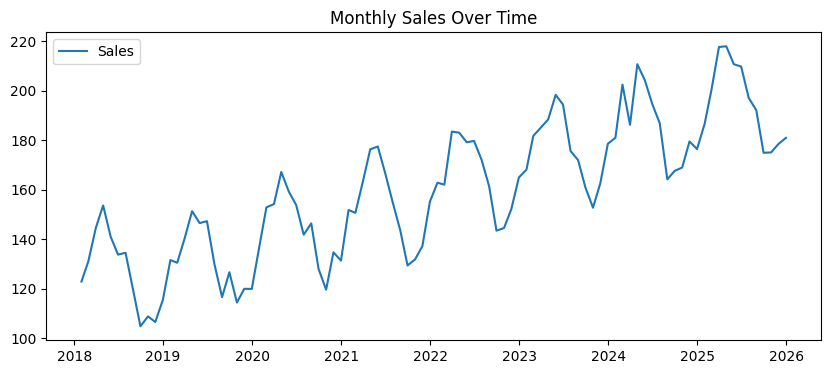

Mean: 159.7053125 Std: 27.60549819198399


In [ ]:
import matplotlib.pyplot as plt
# Create a line plot 
plt.figure(figsize=(10, 4))
plt.plot(ts_data.index, ts_data["sales"], label="Sales")
plt.title("Monthly Sales Over Time")
plt.legend()
plt.show()
print("Mean:", ts_data["sales"].mean(), "Std:", ts_data["sales"].std())

In [51]:
# Seaonal decomposition
decomposition(ts_data["sales"].to_timestamp(), model="additive").show()

In [54]:
# ACF and PACF to check stationarity

acf(ts_data["sales"].to_timestamp()).show()

In [53]:
# PACF plot to check for stationarity
pacf(ts_data["sales"].to_timestamp()).show()

## 3. Setup time series environment

In [29]:
# Setup with pycaret time series
# Note: Using synthetic data; in production use your real time series
print("Setup requires actual time-series data with a date column.")

ts_exp = TimeSeriesExperiment(fh=12, target='sales',n_jobs=1).fit(ts_data)

print("Setup complete")

Setup requires actual time-series data with a date column.
Setup complete


## 4. Compare models

In [30]:
# Example: compare time series models after setup

ts_result = ts_exp.compare_models(sort="RMSE")



In [31]:
# Display the results of the comparison
ts_result.leaderboard


,Model,MASE,RMSSE,MAE,RMSE,MAPE,SMAPE,R2,COVERAGE
0,arima,6.2124,5.4203,56.1603,58.0679,0.3162,0.3787,-16.2261,0.3056
1,auto_arima,7.0443,6.1364,63.6114,65.7243,0.3591,0.4439,-21.2656,0.7222
2,grand_means,7.1640,6.1820,64.6991,66.2076,0.3640,0.4478,-21.5218,0.5833
3,naive,7.4598,6.4765,67.5142,69.4150,0.3847,0.4829,-23.7276,0.8056
4,polytrend,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,croston,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
# Select the best model

ts_best = ts_result.best


In [33]:
# Tune the best model
ts_tuned = ts_exp.tune_model(ts_best, optimize="RMSE")

## 5. Tune best model

In [34]:
# Example: tune the best model
# Tune the best model
ts_tuned = ts_exp.tune_model(ts_best, optimize="RMSE")
ts_tuned.best_params

{'with_intercept': True, 'seasonal_order': (0, 0, 1, 2), 'order': (0, 0, 0)}

## 6. Prediction

In [40]:
# Example predictions and save/load

ts_data.index = ts_data.index.to_period('M')

# Predict using the tuned model with confidence intervals on test data
preds = ts_exp.predict_model(ts_tuned.pipeline, return_pred_int=True)
preds.predictions.head(3)



,y_pred,lower,upper
2024-12-31,176.5264,158.5092,194.5435
2025-01-31,173.9079,149.8254,197.9904
2025-02-28,171.5609,143.6177,199.5042


In [44]:
# Get evaluation metrics for the tuned model
metrics = ts_tuned.metrics
print(metrics)

          MASE   RMSSE      MAE     RMSE    MAPE   SMAPE       R2  COVERAGE
Fold 0  5.8010  5.1538  53.5456  55.4693  0.3197  0.3838 -15.0670    0.3333
Fold 1  6.1074  5.2806  54.9854  56.9105  0.3092  0.3688 -16.2985    0.3333
Fold 2  6.7288  5.8267  59.9498  61.8240  0.3197  0.3834 -17.3129    0.2500
Mean    6.2124  5.4203  56.1603  58.0679  0.3162  0.3787 -16.2261    0.3056
Std     0.3860  0.2919   2.7433   2.7203  0.0050  0.0070   0.9183    0.0393


## 7. Evaluate the forecasting performance

In [42]:
# Evalute the forecast plot and plot diagnostics
forecast(y_true=ts_exp.y_test, y_pred=preds.predictions["y_pred"], 
         lower=preds.predictions["lower"], upper=preds.predictions["upper"], history=
         ts_exp.y_train).show()


## 7 Deploy and save the model

In [ ]:
# use save_model to save the tuned model pipeline
ts_exp.save_model(ts_tuned.pipeline, "Time_Series_Pipeline")
print("Time series model saved as Time_Series_Pipeline.pkl")

Time series model saved as Time_Series_Pipeline.pkl


---
## Summary
- Load time series data
- Engineer features (lags, rolling, calendar)
- Setup with PyCaret time series
- Compare and tune
- Save/load pipeline for forecasting

<small>© 2026 Decoded Limited. All rights reserved.</small>